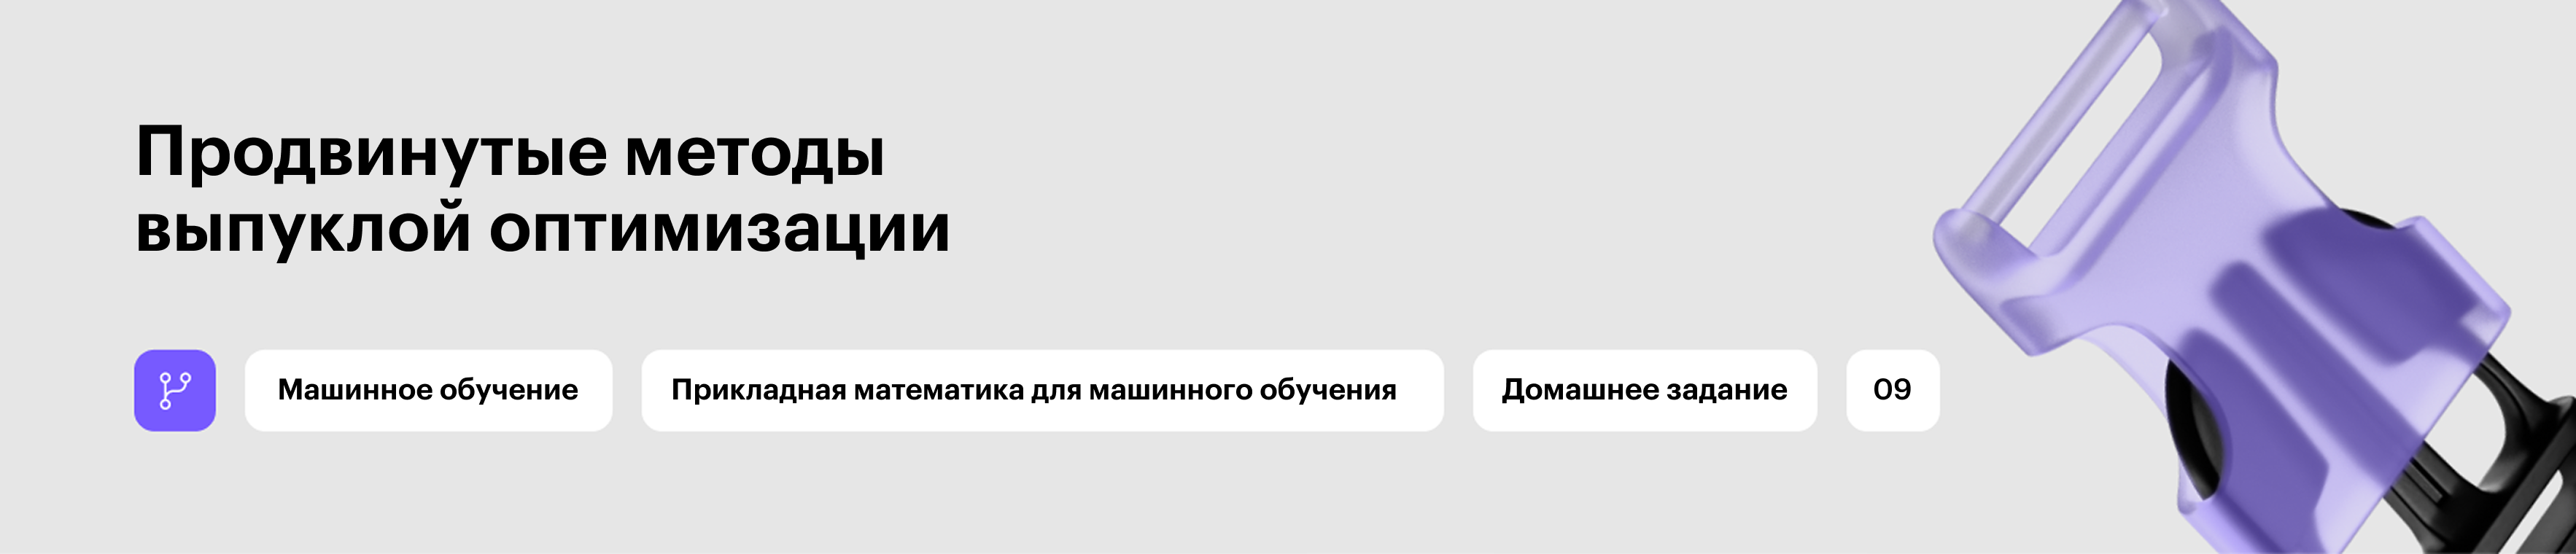

# Домашнее задание 9. Продвинутые методы выпуклой оптимизации (4 балла)


**Неделя 9.** Обозначения: $g_k=\nabla f(x^k)$, $G_k=\nabla^2 f(x^k)$,
$H_k$ — приближение обратного гессиана, $p_k$ — направление,
$x^{k\,+\,1}=x^k+\alpha_kp_k$.

In [ ]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import line_search


def armijo(f, x, g, p, c1=1e-4, beta=0.5, alpha0=1.0, max_trials=60):
    """Дробление для общего направления p; alpha заново начинается с alpha0."""
    slope = float(g @ p)
    if not np.isfinite(slope) or slope >= 0:
        raise ValueError("Для Армихо нужно направление спуска: g @ p < 0")
    fx = float(f(x))
    alpha = float(alpha0)
    for _ in range(max_trials):
        trial = float(f(x + alpha * p))
        if np.isfinite(trial) and trial <= fx + c1 * alpha * slope:
            return alpha
        alpha *= beta
    raise RuntimeError("Не удалось подобрать шаг по Армихо")


def bfgs_update(H, s, y, curvature_tol=1e-10):
    """Возвращает (новая матрица, принято ли обновление). Гессиан не нужен."""
    sy = float(s @ y)
    scale = float(np.linalg.norm(s) * np.linalg.norm(y))
    if not np.isfinite(sy) or sy <= curvature_tol * scale or sy <= 0:
        return H.copy(), False
    rho = 1.0 / sy
    V = np.eye(len(s)) - rho * np.outer(s, y)
    updated = V @ H @ V.T + rho * np.outer(s, s)
    return 0.5 * (updated + updated.T), True


def numerical_gradient(f, x, h=1e-5):
    x = np.asarray(x, dtype=float)
    E = np.eye(len(x))
    return np.array([(f(x+h*e)-f(x-h*e))/(2*h) for e in E])


def numerical_hessian(f, x, h=1e-4):
    """Центральные разности; диагональ считается отдельной формулой."""
    x = np.asarray(x, dtype=float)
    E = np.eye(len(x))
    G = np.zeros((len(x), len(x)))
    fx = f(x)
    for i, ei in enumerate(E):
        G[i, i] = (f(x+h*ei) - 2*fx + f(x-h*ei)) / h**2
        for j in range(i):
            ej = E[j]
            value = (f(x+h*ei+h*ej) - f(x+h*ei-h*ej)
                     - f(x-h*ei+h*ej) + f(x-h*ei-h*ej)) / (4*h**2)
            G[i, j] = G[j, i] = value
    return G


def _run(f, grad, x0, *, kind, hess=None, mode="armijo", search="wolfe",
         gamma=1.0, gtol=1e-6, f_star=None, ftol=1e-4, maxiter=1000,
         max_norm=1e12, keep_H=False):
    """Общий цикл и единая история принятых точек. Время не включает графики.

    mode для Ньютона: full, armijo, shifted. search для BFGS: wolfe,
    armijo, fixed. При f_star != None остановка по |f-f_star| < ftol;
    иначе по норме градиента. Критерий проверяется ДО нового шага.
    """
    if gamma <= 0 or gtol <= 0 or ftol <= 0 or maxiter < 0:
        raise ValueError("Проверьте gamma, точности и maxiter")
    if kind not in {"gd", "newton", "bfgs"}:
        raise ValueError("Неизвестный метод")
    if mode not in {"full", "armijo", "shifted"} or search not in {"wolfe", "armijo", "fixed"}:
        raise ValueError("Неизвестный способ выбора шага")
    x = np.asarray(x0, dtype=float).copy()
    if x.ndim != 1 or not np.all(np.isfinite(x)):
        raise ValueError("x0 должен быть конечным вектором")
    calls = {"f": 0, "grad": 0, "hess": 0}
    def F(z):
        calls["f"] += 1
        return float(f(z))
    def D(z):
        calls["grad"] += 1
        return np.asarray(grad(z), dtype=float)
    started = time.perf_counter()
    H = gamma * np.eye(len(x))
    fx, g = F(x), D(x)
    xs, fs, gs = [x.copy()], [fx], [float(np.linalg.norm(g))]
    alphas, curvatures, updates, shifts, Hs = [], [], [], [], [H.copy()] if keep_H else []
    fallbacks = 0
    status, message = "iteration_limit", "Достигнут предел итераций"
    for k in range(maxiter + 1):
        if not np.isfinite(fx) or not np.all(np.isfinite(g)):
            status, message = "nonfinite", "Неконечная функция или градиент"
            break
        converged = abs(fx - f_star) < ftol if f_star is not None else np.linalg.norm(g) <= gtol
        if converged:
            status, message = "converged", "Выполнен заданный критерий точности"
            break
        if k == maxiter:
            break
        tau = 0.0
        if kind == "gd":
            p = -g
        elif kind == "newton":
            calls["hess"] += 1
            G = np.asarray(hess(x), dtype=float)
            if G.shape != (len(x), len(x)) or not np.all(np.isfinite(G)):
                status, message = "invalid_hessian", "Некорректный гессиан"
                break
            if not np.allclose(G, G.T, rtol=1e-8, atol=1e-10):
                status, message = "invalid_hessian", "Гессиан несимметричен"
                break
            if mode == "shifted":
                tau = max(0.0, 1e-6 - float(np.linalg.eigvalsh(G).min()))
                G = G + tau * np.eye(len(x))
            if mode != "full":
                try:
                    np.linalg.cholesky(G)
                except np.linalg.LinAlgError:
                    status, message = "non_spd", "Нужна положительно определённая модель"
                    break
            try:
                p = np.linalg.solve(G, -g)
            except np.linalg.LinAlgError:
                status, message = "singular", "Гессиан вырожден; шаг не выполнен"
                break
        else:
            p = -H @ g
            if float(g @ p) >= 0:
                H = gamma * np.eye(len(x))
                p = -H @ g
                fallbacks += 1
        full = (kind == "newton" and mode == "full") or (kind == "bfgs" and search == "fixed")
        try:
            if full:
                alpha = 1.0
            elif kind == "bfgs" and search == "wolfe":
                # SciPy реализует поиск с сильными условиями Вульфа
                # Предупреждение сохраняется в журнале результата через счётчик fallback
                with warnings.catch_warnings(record=True):
                    search_result = line_search(F, D, x, p, gfk=g, old_fval=fx,
                                                c1=1e-4, c2=0.9, maxiter=30)
                    alpha = search_result[0]
                if (alpha is None or search_result[-1] is None
                        or not np.isfinite(alpha) or alpha <= 0):
                    alpha = armijo(F, x, g, p)
                    fallbacks += 1
            else:
                alpha = armijo(F, x, g, p)
        except (RuntimeError, ValueError) as error:
            status, message = "line_search_failed", str(error)
            break
        xn = x + alpha * p
        if not np.all(np.isfinite(xn)) or np.linalg.norm(xn) > max_norm:
            status, message = "diverged", "Остановлено: слишком большая или неконечная точка"
            break
        fn, gn = F(xn), D(xn)
        if not np.isfinite(fn) or not np.all(np.isfinite(gn)):
            status, message = "nonfinite_trial", "Пробная точка не принята: неконечные значения"
            break
        if kind == "bfgs":
            s, y = xn - x, gn - g
            H, accepted = bfgs_update(H, s, y)
            curvatures.append(float(s @ y))
            updates.append(accepted)
            if keep_H:
                Hs.append(H.copy())
        x, fx, g = xn, fn, gn
        xs.append(x.copy()); fs.append(fx); gs.append(float(np.linalg.norm(g)))
        alphas.append(float(alpha)); shifts.append(tau)
    return dict(x=x.copy(), fun=fx, grad_norm=float(np.linalg.norm(g)),
                nit=len(xs)-1, status=status, message=message,
                history=np.array(xs), f_history=np.array(fs), grad_history=np.array(gs),
                alphas=np.array(alphas), curvatures=np.array(curvatures),
                updates=np.array(updates, dtype=bool), shifts=np.array(shifts),
                H_history=Hs, fallbacks=fallbacks, calls=calls,
                elapsed=time.perf_counter()-started)


def gradient_descent(f, grad, x0, **kwargs):
    return _run(f, grad, x0, kind="gd", **kwargs)


def newton(f, grad, hess, x0, mode="full", **kwargs):
    return _run(f, grad, x0, kind="newton", hess=hess, mode=mode, **kwargs)


def bfgs(f, grad, x0, search="wolfe", gamma=1.0, **kwargs):
    return _run(f, grad, x0, kind="bfgs", search=search, gamma=gamma, **kwargs)


def quadratic(a=1.0):
    """f = a*x1**2+x2**2; минимум и минимальное значение равны нулю."""
    A = np.diag([2*a, 2.0])
    return (lambda x: float(x @ A @ x / 2), lambda x: A @ x,
            lambda x: A.copy())


def rosenbrock(x):
    u, v = x
    return float(100*(v-u*u)**2 + (1-u)**2)


def rosen_grad(x):
    u, v = x
    return np.array([400*u*(u*u-v)+2*(u-1), 200*(v-u*u)])


def rosen_hess(x):
    u, v = x
    return np.array([[1200*u*u-400*v+2, -400*u], [-400*u, 200.0]])


def report(results):
    print(f"{'Метод':24s} {'шаги':>6s} {'f(x)':>12s} {'||g||':>12s} {'сек.':>9s}  статус; вызовы f/g/G")
    for name, r in results.items():
        print(f"{name:24s} {r['nit']:6d} {r['fun']:12.4e} {r['grad_norm']:12.3e} "
              f"{r['elapsed']:9.4f}  {r['status']}; {r['calls']}")


def plot_results(f, results, title="", f_star=0.0):
    """Графики строятся после измерения времени методов."""
    if not results:
        print("Результатов пока нет: выполните задание выше.")
        return
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    paths = np.concatenate([r['history'] for r in results.values()])
    lo, hi = paths.min(axis=0), paths.max(axis=0)
    pad = max(float(np.max(hi-lo)), 1.0)*0.12
    lo, hi = lo-pad, hi+pad
    U, V = np.meshgrid(np.linspace(lo[0],hi[0],130), np.linspace(lo[1],hi[1],130))
    Z = np.array([f(z) for z in np.c_[U.ravel(), V.ravel()]]).reshape(U.shape)
    axes[1].contour(U,V,Z,levels=18,linewidths=0.6,alpha=0.6)
    for name, r in results.items():
        errors = np.abs(r['f_history']-f_star)
        positive = errors > 0
        axes[0].semilogy(np.flatnonzero(positive),errors[positive],'.-',label=name)
        if np.any(~positive):
            axes[0].annotate(f"{name}: ошибка = 0 на k={np.flatnonzero(~positive)[0]}",
                             xy=(0.02, 0.04+0.06*list(results).index(name)),
                             xycoords='axes fraction', fontsize=8)
        path=r['history']
        axes[1].plot(path[:,0],path[:,1],'.-',label=name)
    axes[0].set(xlabel='Принятые шаги k',ylabel='|f(x^k) - f*|',title='Ошибка по функции')
    axes[1].set(xlabel='x1',ylabel='x2',title='Принятые точки на линиях уровня')
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout(); plt.show()


Реализации методов и визуализация предоставлены, их можно использовать, как на семинаре.
Требуется провести эксперименты, проверить корректность результатов и объяснить различия.
Для каждого метода нужны выполненный код, число шагов, графики ошибок и траекторий, а также вывод.
Одних чисел без кода и объяснения недостаточно. Четыре пункта ниже оцениваются по 1 баллу.

Общие условия: $f_1=x_1^2+x_2^2$, $f_2=100x_1^2+x_2^2$,
$x^0=(10,8)$; аналитические производные;
один критерий $|f(x^k)-f^*|<10^{-4}$, $f^*=0$, не более 2000 шагов.
`nit` — число **принятых** шагов, включая шаг попадания в минимум.
Нужно отдельно сообщать статус завершения. Если достигнут лимит, нельзя объявлять метод сошедшимся.
Нулевая ошибка на логарифмической шкале отмечается отдельно; функция `plot_results` уже это учитывает.


In [ ]:
x0=np.array([10.,8.])
problems={'f1':quadratic(1.),'f2':quadratic(100.)}
experiments={name:{} for name in problems}


## А. Полный метод Ньютона — 1 балл
Запусти полный Ньютон для обеих функций. Сохрани результаты в `experiments[name]['Ньютон']`.
Проверь число шагов и остаток $G_0p_0+g_0$. Объясни, почему вытянутость
линий уровня не мешает одному точному шагу. Построй графики и напиши вывод.


In [ ]:
# TODO: проведи два запуска newton(..., mode='full', f_star=0., ftol=1e-4)


**Твой вывод:** _заполни после вычислений._


## Б. BFGS с поиском длины шага — 1 балл
Используй $H_0=I$, `search='wolfe'`. Сохрани результаты под ключом `'BFGS'`.
Покажи число шагов, статусы, число резервных переходов к Армихо и пропущенных обновлений.
Построй графики; сравни результат с Ньютоном. Почему число шагов может отличаться от
размерности пространства, хотя на семинаре точный линейный поиск дал два шага?


In [ ]:
# TODO: два запуска bfgs(..., gamma=1., search='wolfe', f_star=0., ftol=1e-4)


**Твой вывод:** _заполни после вычислений._


## В. Градиентный спуск с дроблением — 1 балл
Используй предоставленный `gradient_descent` (Армихо: $c_1=10^{-4}$,
дробление $\beta=1/2$, начальная пробная длина 1 на каждой итерации).
Сохрани результаты под ключом `'Градиент'`. Построй общие графики для трёх методов,
сравни число шагов, обращений к функции/производным и измеренное время.
Время визуализации не включай в общее время работы оптимизатора.


In [ ]:
# TODO: два запуска gradient_descent(..., f_star=0., ftol=1e-4), затем общие графики


**Твой вывод:** _заполни после вычислений._


## Г. Начальный масштаб и первый скачок — 1 балл
Теперь отдельно исследуй **BFGS с фиксированным $\alpha=1$** на $f_2$:
$\gamma\in\{1,0.1,0.01, 0.005, 0.001\}$, $H_0=\gamma I$.
Это диагностический эксперимент, не основная схема из пункта Б.
Выбери масштаб без роста функции на первом шаге и с плавным началом траектории
(оцени поворот между первыми двумя перемещениями), вычисли отношение $f(x^1)/f(x^0)$
и построй траектории. Отдельно оцени величину первого перемещения и изменение
его направления на следующем шаге: отсутствие роста функции ещё не означает
визуально плавную траекторию. Объясни связь выбора с $\lambda_{max}(G)=200$;
единственность «лучшей» гаммы не требуется.
Повтори сравнение для Вульфа хотя бы с выбранной гаммой и гаммой 1.


In [ ]:
# TODO: таблица gamma, f(x1)/f(x0), длина первого шага, поворот траектории, nit, status
# TODO: графики для fixed и отдельное сравнение с wolfe


**Твой вывод:** _заполни после вычислений._


## Итог перед сдачей
Проверь, что показаны обе функции, все три метода используют исходный общий критерий,
а эксперимент с фиксированным шагом выделен отдельно. Статус `iteration_limit` или
`line_search_failed` должен быть обсуждён, если он появился. Сохрани результаты выполнения.


In [ ]:
for name,(f,grad,hess) in problems.items():
    if len(experiments[name])<3:
        print(name,': заполни пункты А–В; полного сравнения пока нет.')
        continue
    report(experiments[name])
    for method,r in experiments[name].items():
        assert np.allclose(r['x'],r['history'][-1])
        assert np.isclose(r['fun'],f(r['x']))
        assert r['nit']==len(r['history'])-1


f1 : заполните пункты А–В; полного сравнения пока нет.
f2 : заполните пункты А–В; полного сравнения пока нет.
